In [1]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

print("Setup successful!")
print("TensorFlow version:", tf.__version__)
print("Available GPU:", tf.config.list_physical_devices("GPU"))

Setup successful!
TensorFlow version: 2.21.0
Available GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
import os

print(os.listdir("/content"))

['.config', 'task_dataset.zip', 'sample_data']


In [3]:
import os
import zipfile
import glob

# Find ZIP files uploaded to Colab
zip_files = glob.glob("/content/*.zip")

print("ZIP files found:", zip_files)

if not zip_files:
    raise FileNotFoundError(
        "No ZIP file found. Please upload the dataset ZIP again."
    )

# Use the first ZIP file found
zip_path = zip_files[0]
extract_dir = "/content/casting_dataset"

os.makedirs(extract_dir, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    z.extractall(extract_dir)

print("Dataset extracted successfully!")
print("Location:", extract_dir)

ZIP files found: ['/content/task_dataset.zip']
Dataset extracted successfully!
Location: /content/casting_dataset


In [4]:
import os

for root, dirs, files in os.walk(extract_dir):
    level = root.replace(extract_dir, "").count(os.sep)

    if level > 3:
        dirs[:] = []
        continue

    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:5]:
        print(f"{indent}    {file}")

    if len(files) > 5:
        print(f"{indent}    ... and {len(files) - 5} more files")

casting_dataset/
    casting_data/
        casting_data/
            test/
            train/
    casting_512x512/
        casting_512x512/
            def_front/
                cast_def_0_4615.jpeg
                cast_def_0_3703.jpeg
                cast_def_0_9084.jpeg
                cast_def_0_9980.jpeg
                cast_def_0_6322.jpeg
                ... and 776 more files
            ok_front/
                cast_ok_0_2721.jpeg
                cast_ok_0_8166.jpeg
                cast_ok_0_9732.jpeg
                cast_ok_0_1092.jpeg
                cast_ok_0_7720.jpeg
                ... and 514 more files


In [5]:
import os

DATA_DIR = "/content/casting_dataset/casting_data/casting_data"

TRAIN_DIR = os.path.join(DATA_DIR, "train")
TEST_DIR = os.path.join(DATA_DIR, "test")

print("Training directory exists:", os.path.isdir(TRAIN_DIR))
print("Test directory exists:", os.path.isdir(TEST_DIR))

for split_dir in [TRAIN_DIR, TEST_DIR]:
    print(f"\n{os.path.basename(split_dir).upper()}")

    for class_name in sorted(os.listdir(split_dir)):
        class_dir = os.path.join(split_dir, class_name)

        if os.path.isdir(class_dir):
            image_files = [
                f for f in os.listdir(class_dir)
                if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
            ]

            print(f"{class_name}: {len(image_files)} images")

Training directory exists: True
Test directory exists: True

TRAIN
def_front: 3758 images
ok_front: 2875 images

TEST
def_front: 453 images
ok_front: 262 images


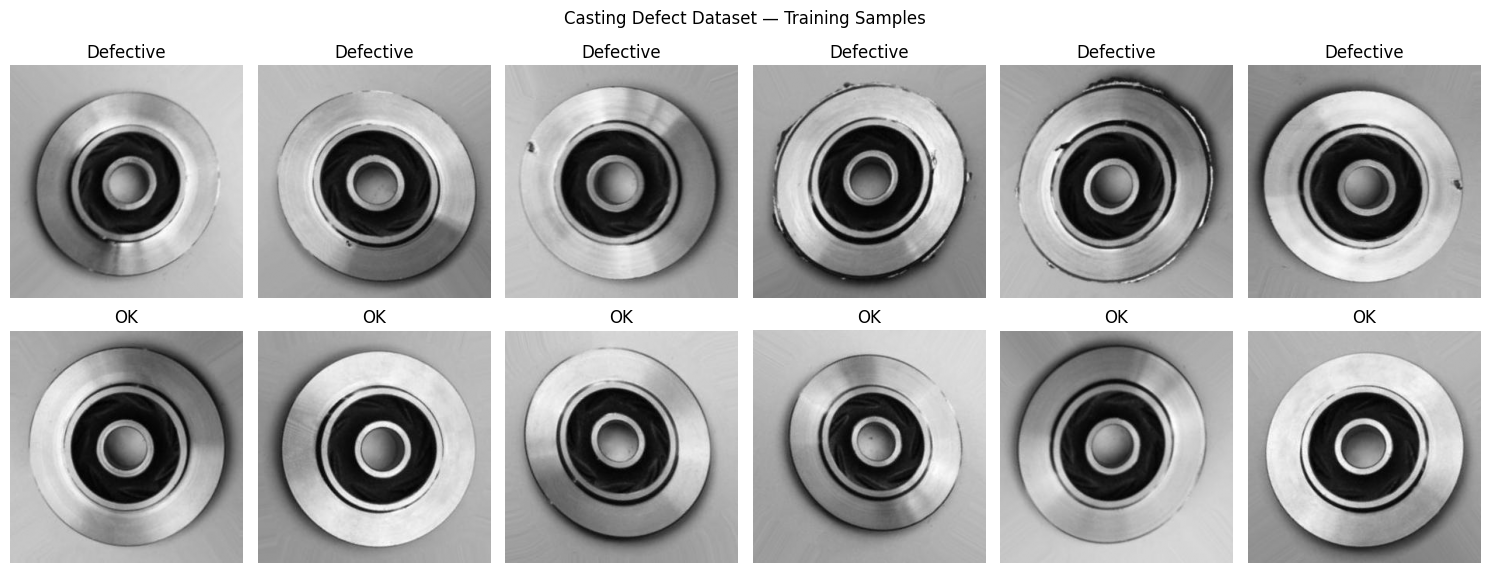

In [6]:
import os
import random
import matplotlib.pyplot as plt
from PIL import Image

random.seed(42)

classes = {
    "Defective": os.path.join(TRAIN_DIR, "def_front"),
    "OK": os.path.join(TRAIN_DIR, "ok_front")
}

fig, axes = plt.subplots(2, 6, figsize=(15, 6))

for row, (class_name, folder) in enumerate(classes.items()):
    image_files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
    ]

    samples = random.sample(image_files, min(6, len(image_files)))

    for col, filename in enumerate(samples):
        image_path = os.path.join(folder, filename)

        with Image.open(image_path) as img:
            axes[row, col].imshow(img.convert("L"), cmap="gray")

        axes[row, col].set_title(class_name)
        axes[row, col].axis("off")

plt.suptitle("Casting Defect Dataset — Training Samples")
plt.tight_layout()
plt.show()

In [7]:
from sklearn.model_selection import train_test_split
from pathlib import Path
import numpy as np

SEED = 42

# Collect image paths and labels
class_to_label = {
    "ok_front": 0,
    "def_front": 1
}

image_paths = []
labels = []

for class_name, label in class_to_label.items():
    folder = Path(TRAIN_DIR) / class_name

    for path in folder.iterdir():
        if path.suffix.lower() in [".jpg", ".jpeg", ".png", ".bmp"]:
            image_paths.append(str(path))
            labels.append(label)

image_paths = np.array(image_paths)
labels = np.array(labels)

# Stratified split preserves class proportions
train_paths, val_paths, y_train, y_val = train_test_split(
    image_paths,
    labels,
    test_size=0.15,
    random_state=SEED,
    stratify=labels
)

print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Test images:", 715)

print("\nTraining class counts:")
print("OK:", np.sum(y_train == 0))
print("Defective:", np.sum(y_train == 1))

print("\nValidation class counts:")
print("OK:", np.sum(y_val == 0))
print("Defective:", np.sum(y_val == 1))

Training images: 5638
Validation images: 995
Test images: 715

Training class counts:
OK: 2444
Defective: 3194

Validation class counts:
OK: 431
Defective: 564


In [8]:
import tensorflow as tf
import numpy as np

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

def load_image(path, label):
    image = tf.io.read_file(path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32)

    return image, tf.cast(label, tf.float32)


def make_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            buffer_size=len(paths),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    ds = ds.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(tf.data.AUTOTUNE)

    return ds


train_ds = make_dataset(train_paths, y_train, training=True)
val_ds = make_dataset(val_paths, y_val)

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Image data type: <dtype: 'float32'>
Minimum pixel value: 0.0
Maximum pixel value: 254.6177520751953


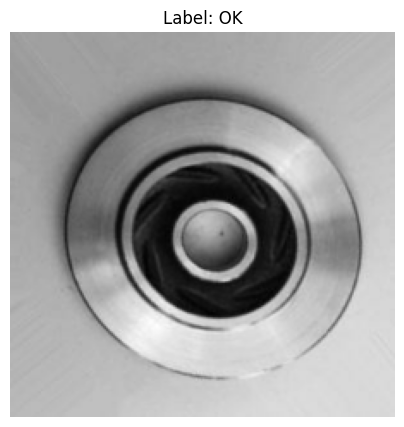

In [9]:
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Image data type:", images.dtype)
    print("Minimum pixel value:", float(tf.reduce_min(images)))
    print("Maximum pixel value:", float(tf.reduce_max(images)))

    plt.figure(figsize=(5, 5))
    plt.imshow(tf.cast(images[0], tf.uint8).numpy())
    plt.title(
        "Label: " +
        ("Defective" if int(labels[0].numpy()) == 1 else "OK")
    )
    plt.axis("off")
    plt.show()

In [10]:
from tensorflow.keras import layers, Model

# Mild augmentation to preserve small surface defects
augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.02),
    layers.RandomZoom(0.05),
], name="augmentation")

# Load pretrained MobileNetV2
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze pretrained layers initially
base_model.trainable = False

# Build the classification model
inputs = layers.Input(shape=(224, 224, 3))

x = augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)

# Output probability of Defective (label 1)
outputs = layers.Dense(1, activation="sigmoid")(x)

model = Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=[
        tf.keras.metrics.BinaryAccuracy(name="accuracy"),
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [11]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

callbacks = [
    ModelCheckpoint(
        "best_casting_model.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True,
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=2,
        min_lr=1e-6,
        verbose=1
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=12,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/12
177/177 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.7488 - loss: 0.5014 - precision: 0.7683 - recall: 0.7979
Epoch 1: val_loss improved from None to 0.23975, saving model to best_casting_model.keras

Epoch 1: finished saving model to best_casting_model.keras
177/177 ━━━━━━━━━━━━━━━━━━━━ 25s 83ms/step - accuracy: 0.8326 - loss: 0.3806 - precision: 0.8489 - recall: 0.8569 - val_accuracy: 0.9216 - val_loss: 0.2398 - val_precision: 0.9386 - val_recall: 0.9220 - learning_rate: 0.0010
Epoch 2/12
176/177 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/step - accuracy: 0.9169 - loss: 0.2356 - precision: 0.9341 - recall: 0.9194
Epoch 2: val_loss improved from 0.23975 to 0.18900, saving model to best_casting_model.keras

Epoch 2: finished saving model to best_casting_model.keras
177/177 ━━━━━━━━━━━━━━━━━━━━ 15s 74ms/step - accuracy: 0.9248 - loss: 0.2163 - precision: 0.9400 - recall: 0.9264 - val_accuracy: 0.9397 - val_loss: 0.1890 - val_precision: 0.9791 - val_recall: 0.9131 - learning_rate: 0.0010

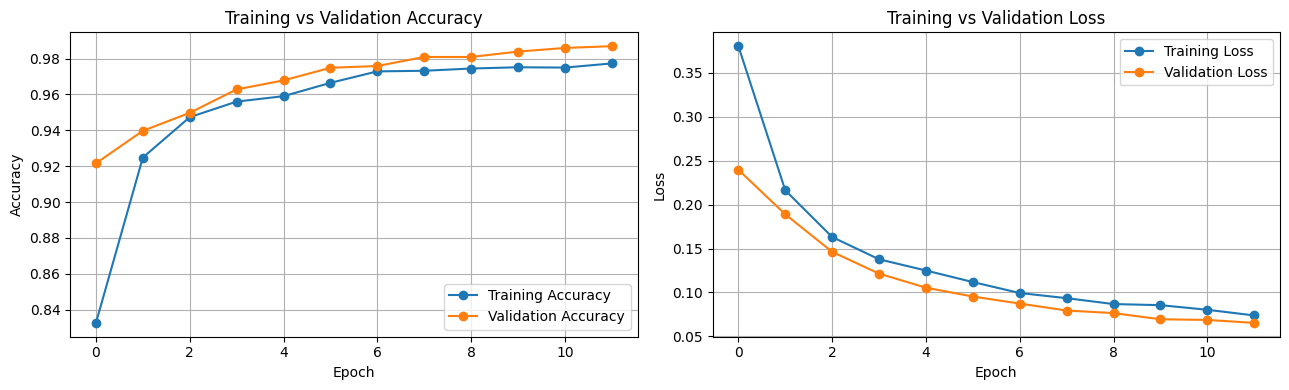

In [12]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Accuracy plot
axes[0].plot(
    history.history["accuracy"],
    label="Training Accuracy",
    marker="o"
)
axes[0].plot(
    history.history["val_accuracy"],
    label="Validation Accuracy",
    marker="o"
)
axes[0].set_title("Training vs Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss plot
axes[1].plot(
    history.history["loss"],
    label="Training Loss",
    marker="o"
)
axes[1].plot(
    history.history["val_loss"],
    label="Validation Loss",
    marker="o"
)
axes[1].set_title("Training vs Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("training_validation_curves.png", dpi=200)
plt.show()

In [13]:
from sklearn.metrics import recall_score
import numpy as np

# Restore the best saved model
model = tf.keras.models.load_model("best_casting_model.keras")

# Predict defect probabilities on validation data
p_val = model.predict(val_ds, verbose=1).ravel()

# y_val already uses:
# 0 = OK
# 1 = Defective

print("Validation samples:", len(y_val))
print("Predicted probabilities:", len(p_val))
print("Actual defective samples:", int(np.sum(y_val == 1)))

32/32 ━━━━━━━━━━━━━━━━━━━━ 5s 96ms/step
Validation samples: 995
Predicted probabilities: 995
Actual defective samples: 564


In [14]:
from sklearn.metrics import recall_score

target_recall = 0.98
thresholds = np.arange(0.01, 1.00, 0.01)

results = []

for t in thresholds:
    pred = (p_val >= t).astype(int)

    defect_recall = recall_score(
        y_val, pred, pos_label=1, zero_division=0
    )

    results.append((t, defect_recall))

eligible = [
    (t, r) for t, r in results
    if r >= target_recall
]

if eligible:
    # Highest threshold that still meets the target recall
    threshold, achieved_recall = max(
        eligible, key=lambda item: item[0]
    )
else:
    # If no threshold achieves the target, use the highest-recall option
    threshold, achieved_recall = max(
        results, key=lambda item: item[1]
    )

print("Selected threshold:", round(float(threshold), 2))
print("Validation defective recall:", round(float(achieved_recall), 4))
print("Target recall:", target_recall)

Selected threshold: 0.52
Validation defective recall: 0.9805
Target recall: 0.98


Found 715 files belonging to 2 classes.
23/23 ━━━━━━━━━━━━━━━━━━━━ 7s 193ms/step
Test images: 715
Selected threshold: 0.52
Test accuracy: 0.9846
Macro F1: 0.9835
Defective precision: 0.9955
Defective recall: 0.9801

Classification report:
              precision    recall  f1-score   support

          OK     0.9665    0.9924    0.9793       262
   Defective     0.9955    0.9801    0.9878       453

    accuracy                         0.9846       715
   macro avg     0.9810    0.9862    0.9835       715
weighted avg     0.9849    0.9846    0.9847       715



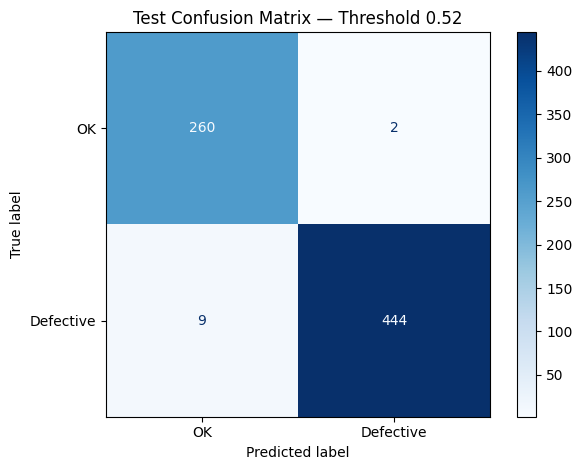

Missed defects: 9
False alarms: 2


In [15]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score
)
import matplotlib.pyplot as plt
import numpy as np

# Load the test dataset in its original order
test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    class_names=["ok_front", "def_front"],
    shuffle=False,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    color_mode="rgb"
)

test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

# True labels: 0 = OK, 1 = Defective
y_test = np.concatenate([
    labels.numpy() for _, labels in test_ds
]).astype(int)

# Predict probabilities of Defective
p_test = model.predict(test_ds, verbose=1).ravel()

# Apply the validation-selected threshold
pred_test = (p_test >= threshold).astype(int)

# Report metrics
print("Test images:", len(y_test))
print("Selected threshold:", threshold)
print("Test accuracy:", round(accuracy_score(y_test, pred_test), 4))
print("Macro F1:", round(
    f1_score(y_test, pred_test, average="macro", zero_division=0), 4
))
print("Defective precision:", round(
    precision_score(y_test, pred_test, pos_label=1, zero_division=0), 4
))
print("Defective recall:", round(
    recall_score(y_test, pred_test, pos_label=1, zero_division=0), 4
))

print("\nClassification report:")
print(classification_report(
    y_test,
    pred_test,
    labels=[0, 1],
    target_names=["OK", "Defective"],
    digits=4,
    zero_division=0
))

# Confusion matrix: rows = actual, columns = predicted
cm = confusion_matrix(y_test, pred_test, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["OK", "Defective"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("Test Confusion Matrix — Threshold 0.52")
plt.tight_layout()
plt.savefig("test_confusion_matrix.png", dpi=200)
plt.show()

# Number of missed defects
missed_defects = int(np.sum((y_test == 1) & (pred_test == 0)))
false_alarms = int(np.sum((y_test == 0) & (pred_test == 1)))

print("Missed defects:", missed_defects)
print("False alarms:", false_alarms)

Total misclassified images: 11
Showing up to four examples.


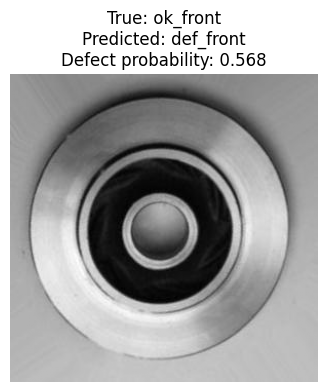

Image: cast_ok_0_1180.jpeg
Likely reason: inspect the surface for subtle defects,
low contrast, reflections, or ambiguous texture.
--------------------------------------------------


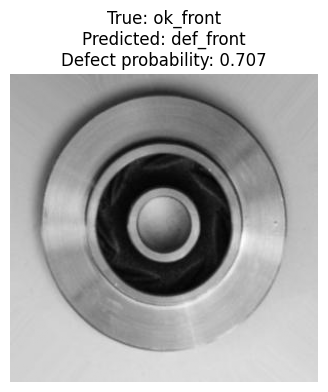

Image: cast_ok_0_7560.jpeg
Likely reason: inspect the surface for subtle defects,
low contrast, reflections, or ambiguous texture.
--------------------------------------------------


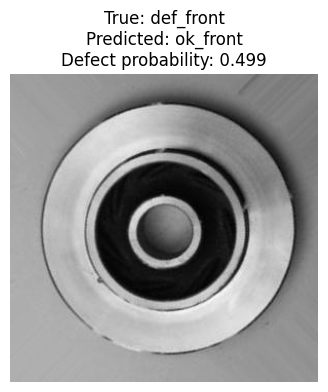

Image: cast_def_0_1413.jpeg
Likely reason: inspect the surface for subtle defects,
low contrast, reflections, or ambiguous texture.
--------------------------------------------------


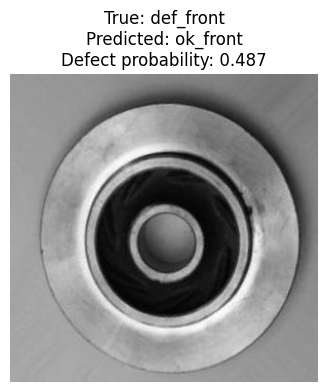

Image: cast_def_0_1422.jpeg
Likely reason: inspect the surface for subtle defects,
low contrast, reflections, or ambiguous texture.
--------------------------------------------------


In [16]:
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

# Find all incorrect predictions
errors = np.where(y_test != pred_test)[0]

print("Total misclassified images:", len(errors))
print("Showing up to four examples.")

for idx in errors[:4]:
    # Recover the original filename
    batch_index = idx // BATCH_SIZE
    position_in_batch = idx % BATCH_SIZE

    # Read the corresponding image path from the test folders
    true_label = int(y_test[idx])
    predicted_label = int(pred_test[idx])

    class_name = "def_front" if true_label == 1 else "ok_front"

    # Locate the image using the deterministic test dataset order
    test_paths_ordered = []
    for cls in ["ok_front", "def_front"]:
        folder = os.path.join(TEST_DIR, cls)
        files = sorted([
            os.path.join(folder, f)
            for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp"))
        ])
        test_paths_ordered.extend(files)

    # image_dataset_from_directory sorts paths by class, then filename
    img_path = test_paths_ordered[idx]

    with Image.open(img_path) as img:
        plt.figure(figsize=(4, 4))
        plt.imshow(img.convert("L"), cmap="gray")

    plt.title(
        f"True: {class_name}\n"
        f"Predicted: {'def_front' if predicted_label == 1 else 'ok_front'}\n"
        f"Defect probability: {p_test[idx]:.3f}"
    )
    plt.axis("off")
    plt.show()

    print("Image:", os.path.basename(img_path))
    print("Likely reason: inspect the surface for subtle defects,")
    print("low contrast, reflections, or ambiguous texture.")
    print("-" * 50)

In [17]:
import os
import shutil

OUTPUT_DIR = "/content/PS32_results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Save the final trained model
model.save(os.path.join(OUTPUT_DIR, "casting_defect_model.keras"))

# Copy existing result plots
for filename in [
    "training_validation_curves.png",
    "test_confusion_matrix.png"
]:
    source = os.path.join("/content", filename)

    if os.path.exists(source):
        shutil.copy2(
            source,
            os.path.join(OUTPUT_DIR, filename)
        )

print("Saved files:")
for filename in os.listdir(OUTPUT_DIR):
    print(filename)

Saved files:
test_confusion_matrix.png
training_validation_curves.png
casting_defect_model.keras


In [18]:
from google.colab import files
import shutil

shutil.make_archive(
    "/content/PS32_results",
    "zip",
    "/content/PS32_results"
)

files.download("/content/PS32_results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>